# Isolation Forest on BATADAL

A static Isolation Forest, trained on clean data and evaluated on the 7 real attacks in Dataset 2.

- **Training:** the Training block of Dataset 1 (5,256 clean hours). The forest sees one hour at a time: the 36 sensor values of that hour.
- **Calibration:** the alarm threshold is set on the Calibration block of Dataset 1, as the lowest threshold inside the false-alarm budget (at most 1% of hours under alarm and at most 1 alarm episode per week). The Validation block checks that it holds on other clean data.
- **Evaluation:** Dataset 2, labelled with the 7 published attack windows (`dataset2_eval.csv`). Detection delay is measured from each attack's real start.
- **Metrics:** attacks detected, detection delay, false alarms, precision, recall, F1, ROC-AUC, PR-AUC, and the BATADAL competition scores S, S_TTD and S_CLF (Taormina et al., 2018).
- **Seeds:** 3, reported as mean ± SD.

Upload `train_scaled.csv`, `val_scaled.csv`, `cal_scaled.csv` and `dataset2_eval.csv` into `/content/files/` (or `/content/`).

## 1. Settings

`UNSCORED_HOURS` leaves hours at the start of each block unscored. The forest needs no history, so the default is 0 and every hour is scored. Setting it to 11 or 23 scores the same hours as a detector with a 12- or 24-hour window; the results barely change, because no attack falls in the first 23 hours of Dataset 2.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import IsolationForest
from IPython.display import display

# Model.
SEEDS = [0, 1, 2]
N_TREES = 200
MAX_SAMPLES = 'auto'

# False-alarm budget, applied on the Calibration block.
MAX_ALARM_FRACTION = 0.01        # at most 1% of clean hours under alarm
MAX_EPISODES_PER_WEEK = 1.0      # at most 1 alarm episode per week
MERGE_GAP_HOURS = 2              # alarm runs at most this many quiet hours apart are one episode
GRACE_HOURS = 3                  # hours after each attack left out of the hourly and false-alarm figures

# BATADAL ranking score weight (Taormina et al. 2018, Eq. 7): S = GAMMA * S_TTD + (1 - GAMMA) * S_CLF.
GAMMA = 0.5
HOURS_PER_WEEK = 168

# Hours left unscored at the start of each block (0 = score every hour).
UNSCORED_HOURS = 0

CONFIG = f'iforest-{N_TREES}trees'
required_files = ['train_scaled.csv', 'val_scaled.csv', 'cal_scaled.csv', 'dataset2_eval.csv']
candidates = [Path('/content/files'), Path('/content'), Path.cwd() / 'files', Path.cwd(),
              Path('data/processed'), Path('../../data/processed')]
DATA_DIR = next((p.resolve() for p in candidates if all((p / f).is_file() for f in required_files)), None)
if DATA_DIR is None:
    raise FileNotFoundError('Upload the four CSV files into /content/files/ (or /content/). Searched: '
                            + ', '.join(str(p) for p in candidates))
OUTPUT_DIR = Path('/content/iforest_results') if Path('/content').exists() else Path('iforest_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Data:', DATA_DIR, '| Output:', OUTPUT_DIR.resolve())

Data: /content | Output: /content/iforest_results


## 2. Load and check the data

Every file must have the same 36 features in the same order, strictly hourly rows and no empty cells. The three Dataset 1 blocks must be entirely normal, with 24-hour gaps between them. Dataset 2 must carry `label` (1 inside the 7 attack windows) and `attack_id` (1 to 7, or 0).

In [2]:
files = {'train': 'train_scaled.csv', 'val': 'val_scaled.csv', 'cal': 'cal_scaled.csv', 'dev': 'dataset2_eval.csv'}
tables = {part: pd.read_csv(DATA_DIR / name, parse_dates=['DATETIME']) for part, name in files.items()}
SPECIAL = {'DATETIME', 'ATT_FLAG', 'label', 'attack_id'}
feature_names = [c for c in tables['train'].columns if c not in SPECIAL]
assert len(feature_names) == 36, f'Expected 36 features, got {len(feature_names)}'
assert sum(c.startswith('S_') for c in feature_names) == 8

for name, df in tables.items():
    assert [c for c in df.columns if c not in SPECIAL] == feature_names, f'{name}: feature columns or order differ'
    assert df['DATETIME'].diff().iloc[1:].eq(pd.Timedelta(hours=1)).all(), f'{name}: rows are not strictly hourly'
    assert np.isfinite(df[feature_names].to_numpy(dtype=float)).all(), f'{name}: empty or non-finite values'
    if name != 'dev':
        assert df['ATT_FLAG'].eq(0).all(), f'{name}: this block must be entirely normal'
for first, second in [('train', 'val'), ('val', 'cal')]:
    gap = (tables[second].DATETIME.iloc[0] - tables[first].DATETIME.iloc[-1]) / pd.Timedelta(hours=1) - 1
    assert gap >= 24, f'{first}/{second}: missing 24-hour gap'
assert (len(tables['train']), len(tables['val']), len(tables['cal']), len(tables['dev'])) == (5256, 1728, 1729, 4177)

dev = tables['dev']
labels = dev['label'].to_numpy(dtype=int)
attack_ids = dev['attack_id'].to_numpy(dtype=int)
assert set(np.unique(labels)) <= {0, 1} and labels.sum() == 492, 'Expected 492 attack hours'
assert set(np.unique(attack_ids)) == set(range(8)), 'Expected attack ids 0 to 7'
assert ((labels == 1) == (attack_ids > 0)).all(), 'label and attack_id disagree'

display(pd.DataFrame([{'block': k, 'rows': len(v), 'start': v.DATETIME.iloc[0], 'end': v.DATETIME.iloc[-1]}
                      for k, v in tables.items()]))
attacks_table = pd.DataFrame([{'id': a, 'start': dev.DATETIME[attack_ids == a].iloc[0],
                               'end': dev.DATETIME[attack_ids == a].iloc[-1], 'hours': int((attack_ids == a).sum())}
                              for a in range(1, 8)])
assert attacks_table.hours.tolist() == [50, 24, 60, 94, 60, 94, 110]
display(attacks_table)

,block,rows,start,end
0,train,5256,2014-01-06,2014-08-12 23:00:00
1,val,1728,2014-08-14,2014-10-24 23:00:00
2,cal,1729,2014-10-26,2015-01-06 00:00:00
3,dev,4177,2016-07-04,2016-12-25 00:00:00


,id,start,end,hours
0,1,2016-09-13 23:00:00,2016-09-16 00:00:00,50
1,2,2016-09-26 11:00:00,2016-09-27 10:00:00,24
2,3,2016-10-09 09:00:00,2016-10-11 20:00:00,60
3,4,2016-10-29 19:00:00,2016-11-02 16:00:00,94
4,5,2016-11-26 17:00:00,2016-11-29 04:00:00,60
5,6,2016-12-06 07:00:00,2016-12-10 04:00:00,94
6,7,2016-12-14 15:00:00,2016-12-19 04:00:00,110


## 3. Scoring, calibration and metrics

- **Score:** the negated `score_samples` of the forest, so a larger score means a more anomalous hour. An hour raises an alarm when its score is above the threshold.
- **Threshold:** candidates are tried from the highest Calibration score down. The search stops at the first one that breaks either budget and keeps the one before it, so every higher threshold is inside the budget too.
- **Detection delay / TTD:** hours from the attack's real start to the first alarm while the attack is ongoing. A missed attack counts its full duration in S_TTD (paper Eqs. 1 to 3).
- **Hourly counts:** one alarm credits one hour, never the whole attack (no point adjustment).

In [3]:
def episode_spans(alarms, merge_gap_hours):
    """Alarm episodes as (first, last) index pairs; runs at most merge_gap_hours apart are merged."""
    alarm_hours = np.flatnonzero(alarms)
    if len(alarm_hours) == 0:
        return []
    breaks = np.flatnonzero(np.diff(alarm_hours) > merge_gap_hours + 1)
    starts = np.concatenate([[alarm_hours[0]], alarm_hours[breaks + 1]])
    ends = np.concatenate([alarm_hours[breaks], [alarm_hours[-1]]])
    return list(zip(starts.tolist(), ends.tolist()))

def clean_block_stats(scores, threshold, merge_gap_hours):
    """False-alarm figures on a block of clean hours."""
    alarms = scores > threshold
    episodes = len(episode_spans(alarms, merge_gap_hours))
    return {'hours': int(len(scores)), 'alarm_hours': int(alarms.sum()),
            'alarm_fraction': float(alarms.mean()), 'episodes': episodes,
            'episodes_per_week': float(episodes / (len(scores) / HOURS_PER_WEEK))}

def in_budget(stats):
    return bool(stats['alarm_fraction'] <= MAX_ALARM_FRACTION and stats['episodes_per_week'] <= MAX_EPISODES_PER_WEEK)

def find_threshold(scores, merge_gap_hours):
    """Lowest threshold inside both budgets, stopping at the first candidate that breaks one."""
    candidates = np.unique(scores)[::-1]
    threshold = candidates[0]
    for candidate in candidates:
        stats = clean_block_stats(scores, candidate, merge_gap_hours)
        if stats['alarm_fraction'] > MAX_ALARM_FRACTION or stats['episodes_per_week'] > MAX_EPISODES_PER_WEEK:
            break
        threshold = candidate
    return float(threshold)

def roc_auc(scores, labels):
    """Area under the ROC curve; tied scores share their average rank."""
    n_pos, n_neg = int((labels == 1).sum()), int((labels == 0).sum())
    if n_pos == 0 or n_neg == 0:
        return None
    _, inverse, counts = np.unique(scores, return_inverse=True, return_counts=True)
    average_rank = (np.cumsum(counts) - (counts - 1) / 2.0)[inverse]
    return float((average_rank[labels == 1].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))

def pr_auc(scores, labels):
    """Area under the precision-recall curve (average precision); tied scores taken together."""
    n_pos = int((labels == 1).sum())
    if n_pos == 0:
        return None
    order = np.argsort(-scores, kind='stable')
    sorted_scores, sorted_labels = scores[order], labels[order]
    last_of_value = np.flatnonzero(np.append(np.diff(sorted_scores) != 0, True))
    true_positives = np.cumsum(sorted_labels == 1)[last_of_value]
    precision = true_positives / (last_of_value + 1)
    recall = true_positives / n_pos
    return float(np.sum(np.diff(np.concatenate([[0.0], recall])) * precision))

def evaluate_scores(scores, threshold, labels, attack_id, attacks, ignore, merge_gap_hours):
    """All metrics for one hourly score on Dataset 2. `attacks` holds id, start index and hours."""
    alarms = scores > threshold
    is_attack = (labels == 1) & ~ignore
    is_clean = (labels == 0) & ~ignore

    per_attack, ttd_ratios = [], []
    for attack in attacks:
        inside = np.flatnonzero((attack_id == attack['id']) & alarms)
        detected = len(inside) > 0
        delay = int(inside[0] - attack['start']) if detected else None
        ttd = delay if detected else attack['hours']                     # paper Eqs. 1-2
        per_attack.append({'id': attack['id'], 'hours': attack['hours'], 'detected': detected,
                           'delay_hours': delay, 'ttd_hours': ttd, 'ttd_ratio': ttd / attack['hours']})
        ttd_ratios.append(ttd / attack['hours'])

    tp = int((alarms & is_attack).sum()); fn = int((~alarms & is_attack).sum())
    fp = int((alarms & is_clean).sum()); tn = int((~alarms & is_clean).sum())
    ratio = lambda a, b: float(a / b) if b > 0 else None
    precision, recall, tnr = ratio(tp, tp + fp), ratio(tp, tp + fn), ratio(tn, tn + fp)
    f1 = None
    if precision is not None and recall is not None and precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)

    clean_hours = fp + tn
    false_episodes = len(episode_spans(alarms & is_clean, merge_gap_hours))
    s_ttd = float(1.0 - np.mean(ttd_ratios)) if ttd_ratios else None              # Eq. 3
    s_clf = (recall + tnr) / 2.0 if recall is not None and tnr is not None else None  # Eq. 6
    s_score = GAMMA * s_ttd + (1 - GAMMA) * s_clf if s_ttd is not None and s_clf is not None else None  # Eq. 7

    known = is_attack | is_clean
    delays = [a['delay_hours'] for a in per_attack if a['detected']]
    metrics = {
        'attacks_detected': int(sum(a['detected'] for a in per_attack)),
        'attacks_total': len(per_attack),
        'missed_attacks': ','.join(str(a['id']) for a in per_attack if not a['detected']),
        'mean_delay_hours': float(np.mean(delays)) if delays else None,
        'median_delay_hours': float(np.median(delays)) if delays else None,
        'false_alarm_episodes': false_episodes,
        'false_alarm_episodes_per_week': ratio(false_episodes, clean_hours / HOURS_PER_WEEK),
        'clean_hours_under_alarm': ratio(fp, clean_hours),
        'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        'precision': precision, 'recall': recall, 'f1': f1,
        'true_negative_rate': tnr, 'tpr': recall, 'tnr': tnr,
        'roc_auc': roc_auc(scores[known], labels[known]),
        'pr_auc': pr_auc(scores[known], labels[known]),
        's_ttd': s_ttd, 's_clf': s_clf, 's_score': s_score}
    return metrics, per_attack, alarms

def plot_timeline(when, scores, threshold, attack_id, alarms, title, output):
    fig, ax = plt.subplots(figsize=(13, 4))
    for i, a in enumerate(sorted(set(attack_id[attack_id > 0]))):
        hours = np.flatnonzero(attack_id == a)
        ax.axvspan(when.iloc[hours[0]], when.iloc[hours[-1]], color='#ecebe7', zorder=0,
                   label='attack window' if i == 0 else None)
    ax.plot(when, scores, lw=0.8, color='#2a78d6', label='anomaly score')
    ax.axhline(threshold, ls='--', c='black', lw=1, label='threshold')
    false_alarms = alarms & (attack_id == 0)
    ax.scatter(when[false_alarms], scores[false_alarms], s=24, marker='^', color='#eb6834', label='false alarm', zorder=4)
    ax.set(xlabel='Hour', ylabel='Anomaly score (larger = more anomalous)')
    ax.set_title(title, loc='left', pad=28)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=4, fontsize=8, frameon=False)
    fig.tight_layout(); fig.savefig(output, dpi=150); plt.close(fig)

## 4. Train one forest per seed

Each forest is fitted on the Training block only and scores every hour of the Calibration and Validation blocks and of Dataset 2. The forests are saved in `models/`.

In [4]:
(OUTPUT_DIR / 'models').mkdir(exist_ok=True)
all_scores = {}
for seed in SEEDS:
    forest = IsolationForest(n_estimators=N_TREES, max_samples=MAX_SAMPLES, random_state=seed, n_jobs=-1)
    forest.fit(tables['train'][feature_names].to_numpy())
    joblib.dump({'model': forest, 'feature_names': feature_names}, OUTPUT_DIR / 'models' / f'seed{seed}.joblib')
    all_scores[seed] = {k: -forest.score_samples(tables[k][feature_names].to_numpy()) for k in ('cal', 'val', 'dev')}
    print(f'Seed {seed}: trained on {len(tables["train"]):,} hours')

Seed 0: trained on 5,256 hours
Seed 1: trained on 5,256 hours
Seed 2: trained on 5,256 hours


## 5. Calibrate and evaluate

For each seed: set the threshold on the Calibration block, check it on the Validation block, and evaluate on Dataset 2. Each seed writes `calibration.json`, `metrics.json`, `per_attack.csv`, `hourly_scores.csv` and `timeline.png` into `seed<n>/`, and one row to `results.csv`.

In [5]:
rows, per_attack_rows = [], []
skip = UNSCORED_HOURS
lab, aid, when = labels[skip:], attack_ids[skip:], dev.DATETIME.iloc[skip:].reset_index(drop=True)
attacks = [{'id': int(a), 'start': int(np.flatnonzero(aid == a)[0]), 'hours': int((aid == a).sum())}
           for a in sorted(set(aid[aid > 0]))]
ignore = np.zeros(len(lab), dtype=bool)
for a in attacks:
    ignore[a['start'] + a['hours']:a['start'] + a['hours'] + GRACE_HOURS] = True
ignore &= aid == 0

for seed in SEEDS:
    sc = {k: v[skip:] for k, v in all_scores[seed].items()}
    threshold = find_threshold(sc['cal'], MERGE_GAP_HOURS)
    calib_stats = clean_block_stats(sc['cal'], threshold, MERGE_GAP_HOURS)
    val_stats = clean_block_stats(sc['val'], threshold, MERGE_GAP_HOURS)
    metrics, per_attack, alarms = evaluate_scores(sc['dev'], threshold, lab, aid, attacks, ignore, MERGE_GAP_HOURS)
    dev_in_budget = None if metrics['false_alarm_episodes_per_week'] is None else bool(
        metrics['false_alarm_episodes_per_week'] <= MAX_EPISODES_PER_WEEK
        and metrics['clean_hours_under_alarm'] <= MAX_ALARM_FRACTION)

    out = OUTPUT_DIR / f'seed{seed}'
    out.mkdir(parents=True, exist_ok=True)
    (out / 'calibration.json').write_text(json.dumps({
        'threshold': threshold, 'scoring': '-IsolationForest.score_samples(X)', 'operator': 'score > threshold',
        'unscored_hours_per_block': skip, 'seed': seed, 'n_estimators': N_TREES,
        'max_samples': MAX_SAMPLES, 'max_alarm_fraction': MAX_ALARM_FRACTION,
        'max_episodes_per_week': MAX_EPISODES_PER_WEEK, 'merge_gap_hours': MERGE_GAP_HOURS,
        'calib_stats': calib_stats, 'val_stats': val_stats, 'val_in_budget': in_budget(val_stats),
        'feature_names': feature_names}, indent=2))
    (out / 'metrics.json').write_text(json.dumps({**metrics, 'threshold': threshold, 'dev_in_budget': dev_in_budget,
                                                 'val_in_budget': in_budget(val_stats), 'gamma': GAMMA}, indent=2))
    pd.DataFrame(per_attack).to_csv(out / 'per_attack.csv', index=False)
    pd.DataFrame({'DATETIME': when, 'score': sc['dev'], 'alarm': alarms.astype(int), 'label': lab,
                  'attack_id': aid, 'grace_hour': ignore.astype(int)}).to_csv(out / 'hourly_scores.csv', index=False)
    plot_timeline(when, sc['dev'], threshold, aid, alarms,
                  f'Dataset 2: Isolation Forest, seed {seed}', out / 'timeline.png')

    p = 'iforest_'
    row = {'config': CONFIG, 'seed': seed, 'unscored_hours': skip,
           p + 'threshold': threshold,
           p + 'calib_alarm_fraction': calib_stats['alarm_fraction'],
           p + 'calib_episodes_per_week': calib_stats['episodes_per_week'],
           p + 'val_alarm_fraction': val_stats['alarm_fraction'],
           p + 'val_episodes_per_week': val_stats['episodes_per_week'],
           p + 'val_in_budget': in_budget(val_stats),
           'merge_gap_hours': MERGE_GAP_HOURS, 'grace_hours': GRACE_HOURS,
           'max_alarm_fraction': MAX_ALARM_FRACTION, 'max_episodes_per_week': MAX_EPISODES_PER_WEEK,
           'scored_hours': int(len(lab)), 'attack_hours': int((lab == 1).sum()),
           'clean_hours': int(((lab == 0) & ~ignore).sum())}
    row.update({p + k: v for k, v in metrics.items()})
    row[p + 'dev_in_budget'] = dev_in_budget
    rows.append(row)
    per_attack_rows += [{'seed': seed, **r} for r in per_attack]
    print(f'Seed {seed} | attacks {metrics["attacks_detected"]}/7 | precision {metrics["precision"]:.3f} | '
          f'recall {metrics["recall"]:.3f} | F1 {metrics["f1"]:.3f} | S {metrics["s_score"]:.3f} | '
          f'validation in budget {in_budget(val_stats)}')

results = pd.DataFrame(rows)
results.to_csv(OUTPUT_DIR / 'results.csv', index=False)
pd.DataFrame(per_attack_rows).to_csv(OUTPUT_DIR / 'all_per_attack.csv', index=False)
print('Saved', OUTPUT_DIR / 'results.csv')

Seed 0 | attacks 5/7 | precision 0.318 | recall 0.028 | F1 0.052 | S 0.462 | validation in budget False
Seed 1 | attacks 6/7 | precision 0.246 | recall 0.028 | F1 0.051 | S 0.446 | validation in budget False
Seed 2 | attacks 5/7 | precision 0.289 | recall 0.026 | F1 0.048 | S 0.461 | validation in budget True
Saved /content/iforest_results/results.csv


## 6. Results

Per seed, then in the layout of Table 4 of Taormina et al. (2018), then mean ± SD over the seeds. The S-score depends on delays across only 7 attacks, so differences of a few hundredths are within noise.

In [6]:
p = 'iforest_'
show = lambda cols: results[['seed'] + [p + c for c in cols]].rename(columns=lambda c: c.replace(p, ''))
print(f'{int(results.scored_hours.iloc[0]):,} scored hours: {int(results.attack_hours.iloc[0])} attack, '
      f'{int(results.clean_hours.iloc[0]):,} clean')
display(show(['attacks_detected', 'missed_attacks', 'mean_delay_hours', 'tp', 'fp', 'fn', 'tn', 'precision',
              'recall', 'f1', 'roc_auc', 'pr_auc', 'false_alarm_episodes_per_week', 'clean_hours_under_alarm',
              'val_in_budget', 'dev_in_budget']).round(3))

print('Layout of Table 4 of Taormina et al. (2018):')
table4 = show(['attacks_detected', 's_score', 's_ttd', 's_clf', 'tpr', 'tnr', 'tp', 'fp', 'tn', 'fn']).rename(
    columns={'attacks_detected': '# attacks detected', 's_score': 'S', 's_ttd': 'S_TTD', 's_clf': 'S_CLF',
             'tpr': 'TPR', 'tnr': 'TNR', 'tp': 'TP', 'fp': 'FP', 'tn': 'TN', 'fn': 'FN'})
display(table4.round(3))
table4.to_csv(OUTPUT_DIR / 'table4_layout.csv', index=False)

summary_metrics = ['attacks_detected', 'mean_delay_hours', 'false_alarm_episodes_per_week', 'precision', 'recall',
                   'f1', 'roc_auc', 'pr_auc', 's_ttd', 's_clf', 's_score']
values = results[[p + m for m in summary_metrics]].apply(pd.to_numeric, errors='coerce')
summary = pd.DataFrame({'mean': values.mean().values, 'std': values.std(ddof=1).values}, index=summary_metrics)
print(f'Mean ± SD over {len(SEEDS)} seeds:')
display(summary.round(3))
summary.to_csv(OUTPUT_DIR / 'summary_mean_sd.csv')

4,177 scored hours: 492 attack, 3,664 clean


,seed,attacks_detected,missed_attacks,mean_delay_hours,tp,fp,fn,tn,precision,recall,f1,roc_auc,pr_auc,false_alarm_episodes_per_week,clean_hours_under_alarm,val_in_budget,dev_in_budget
0,0,5,"2,5",33.400,14,30,478,3634,0.318,0.028,0.052,0.644,0.212,1.284,0.008,False,False
1,1,6,5,37.667,14,43,478,3621,0.246,0.028,0.051,0.645,0.202,1.651,0.012,False,False
2,2,5,"2,5",33.600,13,32,479,3632,0.289,0.026,0.048,0.640,0.197,1.376,0.009,True,False


Layout of Table 4 of Taormina et al. (2018):


,seed,# attacks detected,S,S_TTD,S_CLF,TPR,TNR,TP,FP,TN,FN
0,0,5,0.462,0.415,0.510,0.028,0.992,14,30,3634,478
1,1,6,0.446,0.384,0.508,0.028,0.988,14,43,3621,478
2,2,5,0.461,0.413,0.509,0.026,0.991,13,32,3632,479


Mean ± SD over 3 seeds:


,mean,std
attacks_detected,5.333,0.577
mean_delay_hours,34.889,2.408
false_alarm_episodes_per_week,1.437,0.191
precision,0.284,0.037
recall,0.028,0.001
f1,0.051,0.002
roc_auc,0.643,0.003
pr_auc,0.204,0.008
s_ttd,0.404,0.017
s_clf,0.509,0.001


## 7. Figures

Confusion matrices and the main metrics per seed. Timelines are saved per seed in `seed<n>/timeline.png`.

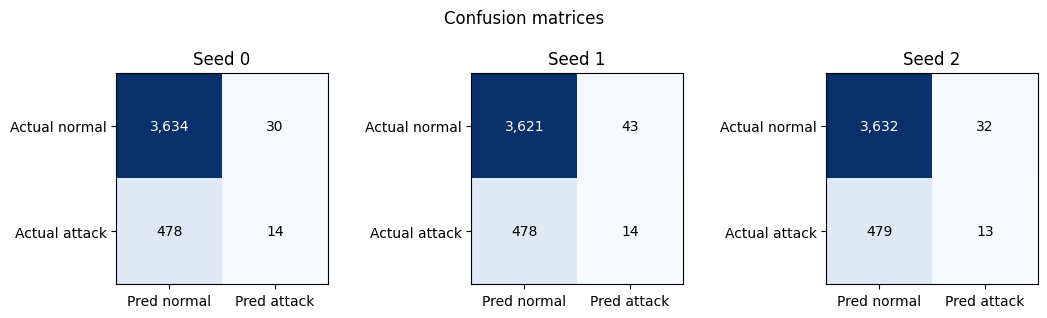

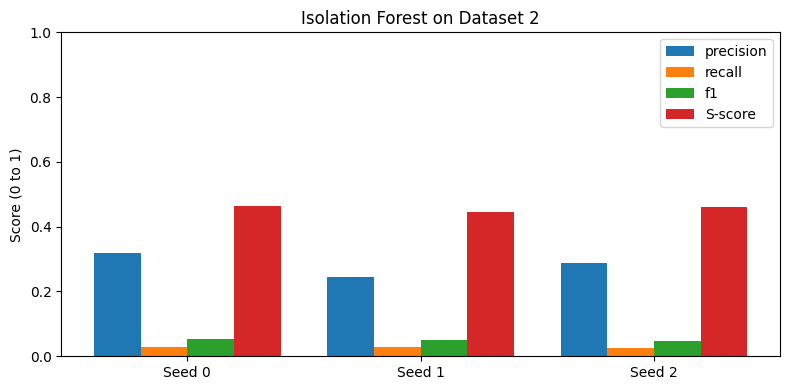

In [7]:
fig, axes = plt.subplots(1, len(SEEDS), figsize=(3.6 * len(SEEDS), 3.2))
for ax, (_, m) in zip(np.atleast_1d(axes), results.iterrows()):
    matrix = np.array([[m[p + 'tn'], m[p + 'fp']], [m[p + 'fn'], m[p + 'tp']]], dtype=int)
    ax.imshow(matrix, cmap='Blues')
    ax.set_xticks([0, 1], ['Pred normal', 'Pred attack']); ax.set_yticks([0, 1], ['Actual normal', 'Actual attack'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{matrix[i, j]:,}', ha='center', va='center',
                    color='white' if matrix[i, j] > matrix.max() / 2 else 'black')
    ax.set_title(f'Seed {int(m.seed)}')
fig.suptitle('Confusion matrices'); fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrices.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
bar_metrics = ['precision', 'recall', 'f1', 's_score']
xs, width = np.arange(len(results)), 0.2
for i, metric in enumerate(bar_metrics):
    ax.bar(xs + (i - (len(bar_metrics) - 1) / 2) * width, results[p + metric].astype(float), width,
           label='S-score' if metric == 's_score' else metric)
ax.set_xticks(xs, [f'Seed {s}' for s in results.seed]); ax.set_ylim(0, 1); ax.set_ylabel('Score (0 to 1)')
ax.set_title('Isolation Forest on Dataset 2'); ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'seed_metrics.png', dpi=150); plt.show()

## 8. Download the results (Colab)

In [8]:
import shutil
archive = shutil.make_archive(str(OUTPUT_DIR), 'zip', root_dir=OUTPUT_DIR)
print('Results ZIP:', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Not running in Colab: the ZIP is saved next to the results folder.')

Results ZIP: /content/iforest_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>